# Дипломски рад

**Аутор:** Тијана Ђоковић

Анализа фактора који се односе на опредељење за СТЕМ смер у средњој школи (упитник, подаци у `STEM.xlsx`). У наставку: припрема података, дефиниција циљне променљиве, описна анализа и основни статистички тестови.

# 1. Припрема података

## 1.1. Учитавање и преглед скупа података

Учитавамо одговоре из Excel фајла (`STEM.xlsx` — без измене из кода), користимо **pandas** за табеларне податке, **seaborn/matplotlib** за графике и **scipy.stats** за тестове.

Пре моделовања (ако се додаје касније) вредно је проверити недостајуће вредности, типове колона и да ли текстуални одговори имају неочекиване варијанте (размак, различит писмо).

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ttest_ind, chi2_contingency

sns.set_style("whitegrid")


In [3]:
df = pd.read_excel("STEM.xlsx")
df.head()

,Timestamp,Пол:,Година рођења:,Похађам средњу школу:,Смер:,Разред:,Одрастао/ла сам у:,Основну школу сам завршио/ла у:,Занимање твоје мајке:,Стручна спрема твоје мајке:,...,Процени који од фактора је имао колико утицаја на твоју одлуку за упис и похађање изабраног смера. [Вршњаци],Процени који од фактора је имао колико утицаја на твоју одлуку за упис и похађање изабраног смера. [Наставник],"Процени који од фактора је имао колико утицаја на твоју одлуку за упис и похађање изабраног смера. [Медији (телевизија, друштвене мреже, интернет, блогови итд)]",Процени који од фактора је имао колико утицаја на твоју одлуку за упис и похађање изабраног смера. [Склоност ка одређеној групи предмета],Процени који од фактора је имао колико утицаја на твоју одлуку за упис и похађање изабраног смера. [Добра проходност на факултет који желим да студирам по завршетку средње школе],Процени који од фактора је имао колико утицаја на твоју одлуку за упис и похађање изабраног смера. [Интересовање за занимање којим желим да се бавим у будућности],Процени колико је ко од запослених у основној школи водио са тобом разговор и саветовао те око одабира средње школе и професионалне оријентације. [Школски психолог/педагог],Процени колико је ко од запослених у основној школи водио са тобом разговор и саветовао те око одабира средње школе и професионалне оријентације. [Разредни старешина],Процени колико је ко од запослених у основној школи водио са тобом разговор и саветовао те око одабира средње школе и професионалне оријентације. [Предметни наставник],Процени колико је ко од запослених у основној школи водио са тобом разговор и саветовао те око одабира средње школе и професионалне оријентације. [Неко друго стручно лице]
0,2023-11-28 21:50:20.078,мушки,2007,„Јован Јовановић Змај“ Нови Сад,специјализовано одељење за ученике са посебним...,2.0,већем граду,већем граду,preduzetnica,завршен факултет,...,1 - нимало,2 - мало,3 - средње,5 - изразито,5 - изразито,5 - изразито,1 - нимало,1 - нимало,1 - нимало,1 - нимало
1,2023-11-28 21:52:10.331,женски,2005,„Јован Јовановић Змај“ Нови Сад,природно-математички,4.0,варошици,варошици,Radnik,завршена виша школа,...,1 - нимало,4 - доста,4 - доста,5 - изразито,5 - изразито,4 - доста,1 - нимало,2 - мало,4 - доста,1 - нимало
2,2023-11-28 21:52:16.136,женски,2005,„Јован Јовановић Змај“ Нови Сад,специјализовано одељење за ученике са посебним...,4.0,већем граду,већем граду,Lekar,завршен факултет,...,1 - нимало,1 - нимало,1 - нимало,2 - мало,4 - доста,1 - нимало,1 - нимало,1 - нимало,1 - нимало,1 - нимало
3,2023-11-28 21:52:17.193,женски,2007,„Јован Јовановић Змај“ Нови Сад,билингвално одељење (одељење у коме се део нас...,3.0,већем граду,већем граду,Diplomirani ekonomista,завршен факултет,...,3 - средње,4 - доста,2 - мало,5 - изразито,3 - средње,1 - нимало,5 - изразито,2 - мало,3 - средње,1 - нимало
4,2023-11-28 21:52:41.167,женски,2008,„Јован Јовановић Змај“ Нови Сад,природно-математички,1.0,селу,селу,Ekonomista,завршен факултет,...,1 - нимало,3 - средње,1 - нимало,3 - средње,4 - доста,4 - доста,4 - доста,5 - изразито,4 - доста,4 - доста


## Основне информације о скупу података

`info()` приказује типове и недостајуће вредности по колони; `describe()` сажетак за нумеричке колоне; `shape` број редова и колона.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1044 entries, 0 to 1043
Columns: 105 entries, Timestamp to Процени колико је ко од запослених у основној школи водио са тобом разговор и саветовао те око одабира средње школе и професионалне оријентације. [Неко друго стручно лице]
dtypes: datetime64[ns](1), float64(1), int64(15), object(88)
memory usage: 856.5+ KB


In [5]:
df.describe()

,Timestamp,Година рођења:,Разред:,Најчешћа оцена из наведених предмета у основној школи ми је била: [Српски језик и књижевност],Најчешћа оцена из наведених предмета у основној школи ми је била: [Енглески језик],Најчешћа оцена из наведених предмета у основној школи ми је била: [2. страни језик],Најчешћа оцена из наведених предмета у основној школи ми је била: [Историја],Најчешћа оцена из наведених предмета у основној школи ми је била: [Географија],Најчешћа оцена из наведених предмета у основној школи ми је била: [Биологија],Најчешћа оцена из наведених предмета у основној школи ми је била: [Математика],Најчешћа оцена из наведених предмета у основној школи ми је била: [Информатика],Најчешћа оцена из наведених предмета у основној школи ми је била: [Физика],Најчешћа оцена из наведених предмета у основној школи ми је била: [Хемија],Најчешћа оцена из наведених предмета у основној школи ми је била: [Музичка култура],Најчешћа оцена из наведених предмета у основној школи ми је била: [Ликовна култура],Најчешћа оцена из наведених предмета у основној школи ми је била: [Физичко васпитање],Најчешћа оцена из наведених предмета у основној школи ми је била: [Техника и технологија]
count,1044,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000
mean,2023-12-19 18:51:07.355917568,2006.895594,2.381322,4.766284,4.796935,4.800766,4.818008,4.819923,4.802682,4.546935,4.909004,4.585249,4.598659,4.954023,4.954981,4.966475,4.909004
min,2023-11-28 21:50:20.078000,2005.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,2023-11-29 21:27:34.893999872,2006.000000,1.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,4.000000,5.000000,4.000000,4.000000,5.000000,5.000000,5.000000,5.000000
50%,2023-12-14 09:02:53.044000,2007.000000,2.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000
75%,2023-12-18 10:52:50.224750080,2008.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000
max,2024-05-19 13:14:19.370000,2011.000000,8.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000
std,NaN,1.211807,1.282004,0.549534,0.563299,0.556113,0.541137,0.554028,0.555071,0.824307,0.408861,0.771877,0.776475,0.333196,0.328984,0.306257,0.418136


In [7]:
print('Димензије:', df.shape)

Димензије: (1044, 105)


## 1.2. Дефинисање циљне променљиве (STEM vs NON-STEM)

Циљна променљива је **бинарна**: ученик је на једном од наведених *СТЕМ* смерава у гимназији (`1`) или није (`0`). Вредност градимо из колоне **`Смер:`** (како је у анкети), без измене изворног Excel фајла.

Листа `stem_smerovi` треба да одговара дефиницији СТЕМ-а у тексту рада; ако се дефиниција промени, мења се само ова листа и поново покрећу ћелије испод.


In [8]:
stem_smerovi = [
    'природно-математички',
    'специјализовано одељење за ученике са посебним способностима за информатику',
    'специјализовано одељење за ученике са посебним способностима за математику',
    'специјализовано одељење за ученике са посебним способностима за биологију и хемију',
    'специјализовано одељење за ученике са посебним способностима за физику',
]

# Колона STEM: 1 = смер из листе изнад, 0 = остали смерави; NaN у Смер: третирамо као 0
df['STEM'] = df['Смер:'].apply(lambda x: 1 if pd.notna(x) and x in stem_smerovi else 0)

print('Апсолутне фреквенције:')
print(df['STEM'].value_counts().sort_index())
print('\nУдео (нормализовано):')
print(df['STEM'].value_counts(normalize=True).round(4))

# Унапред упозорење ако у подацима има вредности смера које нису у листи (провера конзистентности)
sve_smerove = df['Смер:'].dropna().unique()
nepoznato = [s for s in sorted(sve_smerove, key=str) if s not in stem_smerovi and s is not np.nan]
print(f"\nБрој различитих 'осталих' смерава (није у stem_smerovi): {len(nepoznato)}")

Апсолутне фреквенције:
STEM
0    610
1    434
Name: count, dtype: int64

Удео (нормализовано):
STEM
0    0.5843
1    0.4157
Name: proportion, dtype: float64

Број различитих 'осталих' смерава (није у stem_smerovi): 5


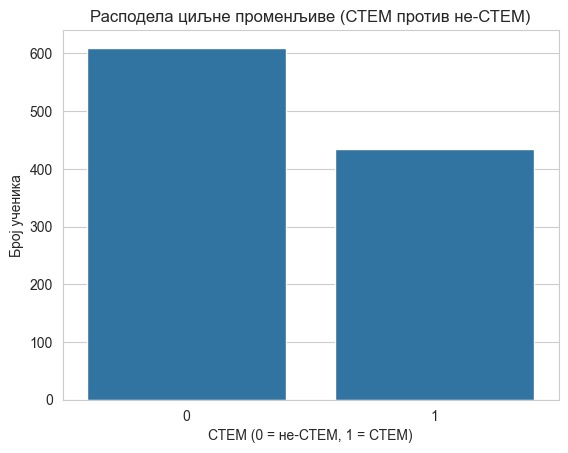

In [9]:
sns.countplot(x='STEM', data=df)
plt.xlabel('СТЕМ (0 = не-СТЕМ, 1 = СТЕМ)')
plt.ylabel('Број ученика')
plt.title('Расподела циљне променљиве (СТЕМ против не-СТЕМ)')
plt.show()

### Искључивање колона за даље моделовање (описни / слободни текст)

Следеће колоне су **описног карактера** (слободан текст или сиров временски печат) и у овом облику нису погодне за директан унос у класичне предиктивне моделе без NLP или додатног кодирања. У наставку их избацујемо из матрице обележја `X`.

- `Timestamp`
- `Занимање твоје мајке:`, `Занимање твог оца:`
- `Зашто сте изабрали да упишите Гимназију?`, `Зашто сте изабрали да упишете овај смер?`

Циљна променљива остаје у `y` (колона `STEM` у `df`).


In [10]:
cols_to_drop = [
    'Timestamp',
    'Занимање твоје мајке:',
    'Занимање твог оца:',
    'Зашто сте изабрали да упишите Гимназију?',
    'Зашто сте изабрали да упишете овај смер?',
]
X = df.drop(columns=cols_to_drop)
y = df['STEM']

print('Колоне у X (укључујући STEM за EDA графике са hue):')
print(X.columns.tolist())

Колоне у X (укључујући STEM за EDA графике са hue):
['Пол:', 'Година рођења:', 'Похађам средњу школу:', 'Смер:', 'Разред:', 'Одрастао/ла сам у:', 'Основну школу сам завршио/ла у:', 'Стручна спрема твоје мајке:', 'Стручна спрема твог оца:', 'Колико има деце у твојој породици, рачунајући и тебе (упиши број):', 'Какав си био/ла ђак у основној школи?', 'Најомиљенији предмет:', 'Други омиљени предмет (омиљени предмет, мање омиљени од претходног):', 'Трећи омиљени предмет (омиљени предмет, мање омиљени од претходна два):', 'Колико ти је поједини предмет био тежак у основној школи?  [Српски језик и књижевност]', 'Колико ти је поједини предмет био тежак у основној школи?  [Енглески језик]', 'Колико ти је поједини предмет био тежак у основној школи?  [2. страни језик]', 'Колико ти је поједини предмет био тежак у основној школи?  [Историја]', 'Колико ти је поједини предмет био тежак у основној школи?  [Географија]', 'Колико ти је поједини предмет био тежак у основној школи?  [Биологија]', 'Колик

## Анализа неких предмета који припадају СТЕМ областима

Поређење расподеле најчешћих оцена из математике, физике и (као референца) српског језика. Кутијасти дијаграм показује медијан, квартиле и изласке.

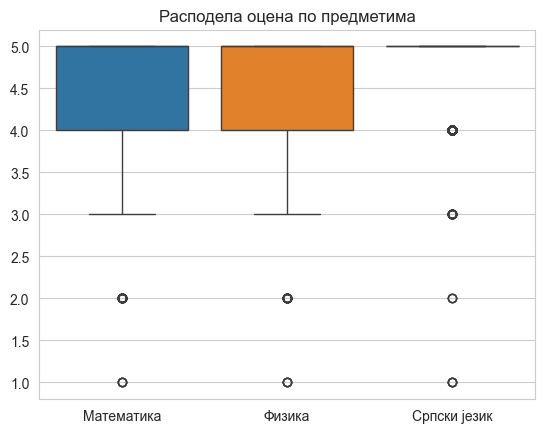

In [11]:
data = X[[
'Најчешћа оцена из наведених предмета у основној школи ми је била: [Математика]',
'Најчешћа оцена из наведених предмета у основној школи ми је била: [Физика]',
'Најчешћа оцена из наведених предмета у основној школи ми је била: [Српски језик и књижевност]'
]]

sns.boxplot(data=data)

plt.xticks(
    ticks=[0, 1, 2],
    labels=['Математика', 'Физика', 'Српски језик']
)

plt.title('Расподела оцена по предметима')
plt.show()

## Анализа категоријских обележја

Фреквенције и графикони за изабране категоријске променљиве (нпр. пол, величина места одрастања).

In [12]:
X['Пол:'].value_counts()

Пол:
женски    715
мушки     329
Name: count, dtype: int64

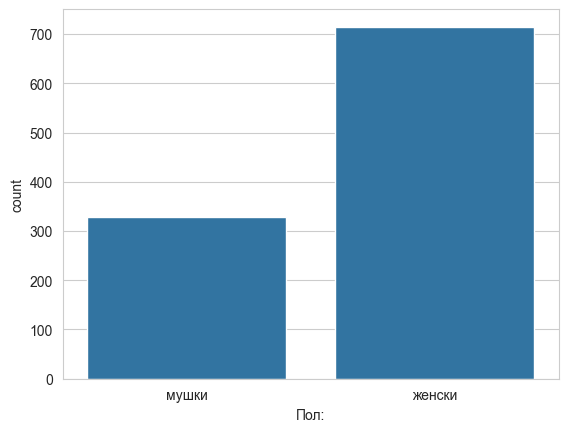

In [13]:
sns.countplot(x='Пол:', data=X)
plt.show()

In [14]:
X['Одрастао/ла сам у:'].value_counts()

Одрастао/ла сам у:
већем граду    712
селу           139
мањем граду     98
варошици        95
Name: count, dtype: int64

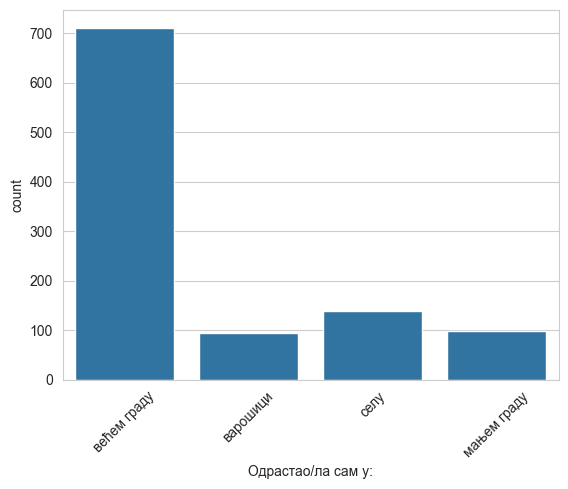

In [15]:
sns.countplot(x='Одрастао/ла сам у:', data=X)
plt.xticks(rotation=45)
plt.show()

## Однос категоријских обележја и СТЕМ опредељења

Упоредни приказ (hue = STEM) помаже да се види да ли се расподела категорије разликује између СТЕМ и не-СТЕМ групе.

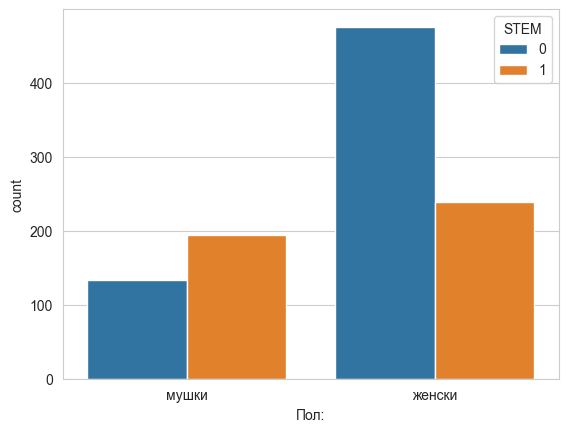

In [16]:
sns.countplot(x='Пол:', hue='STEM', data=X)
plt.show()

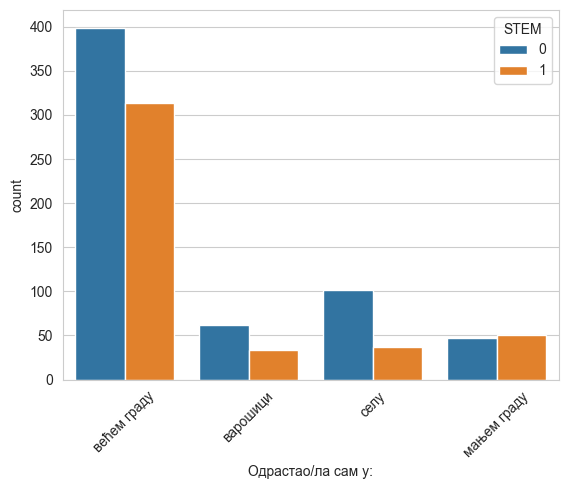

In [17]:
sns.countplot(x='Одрастао/ла сам у:', hue='STEM', data=X)
plt.xticks(rotation=45)
plt.show()

## Боксплот

Поређење расподеле оцена из математике између групе STEM и не-STEM.

C:\Users\hplay\AppData\Local\Temp\ipykernel_15044\1180486983.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['НЕ-СТЕМ', 'СТЕМ'])


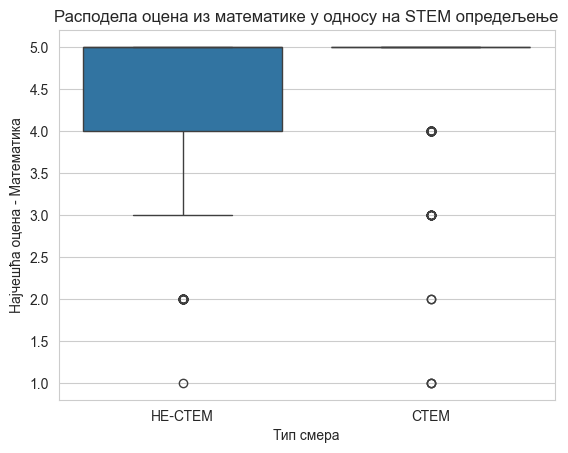

In [18]:
ax = sns.boxplot(
    x='STEM',
    y='Најчешћа оцена из наведених предмета у основној школи ми је била: [Математика]',
    data=X,
)
ax.set_xticklabels(['НЕ-СТЕМ', 'СТЕМ'])
plt.ylabel('Најчешћа оцена - Математика')
plt.xlabel('Тип смера')
plt.title('Расподела оцена из математике у односу на STEM опредељење')
plt.show()

## Корелациона матрица

Ликерт ставови се претварају у бројеве (види ћелију испод); затим се за изабране нумеричке колоне рачуна Пирсонова корелација. Матрица је илустративна — за закључке о узрочности потребна је додатна анализа.

Питања са одговорима у облику *„1 - нимало“*, *„2 - мало“*, … мапирамо на цео број (1–5) преузимањем дела пре цртице. То омогућава корелацију и топлотну мапу; **није** исто што и формално моделирање као континуиране променљиве, али је уобичајен корак у описној анализи.

In [19]:
def extract_number(x):
    if pd.isna(x):
        return x
    return int(str(x).split('-')[0].strip())


likert_cols = [col for col in X.columns if 'Колико ти је' in col or 'Процени' in col]

for col in likert_cols:
    X[col] = X[col].apply(extract_number)

In [20]:
selected_columns = [
    'STEM',
    'Најчешћа оцена из наведених предмета у основној школи ми је била: [Математика]',
    'Најчешћа оцена из наведених предмета у основној школи ми је била: [Физика]',
    'Најчешћа оцена из наведених предмета у основној школи ми је била: [Информатика]',
    'Колико ти је поједини предмет био занимљив у основној школи?  [Математика]',
    'Колико ти је поједини предмет био занимљив у основној школи?  [Физика]',
    'Колико ти је поједини предмет био тежак у основној школи?  [Математика]',
    'Колико ти је поједини предмет био тежак у основној школи?  [Физика]',
]

corr = X[selected_columns].corr()

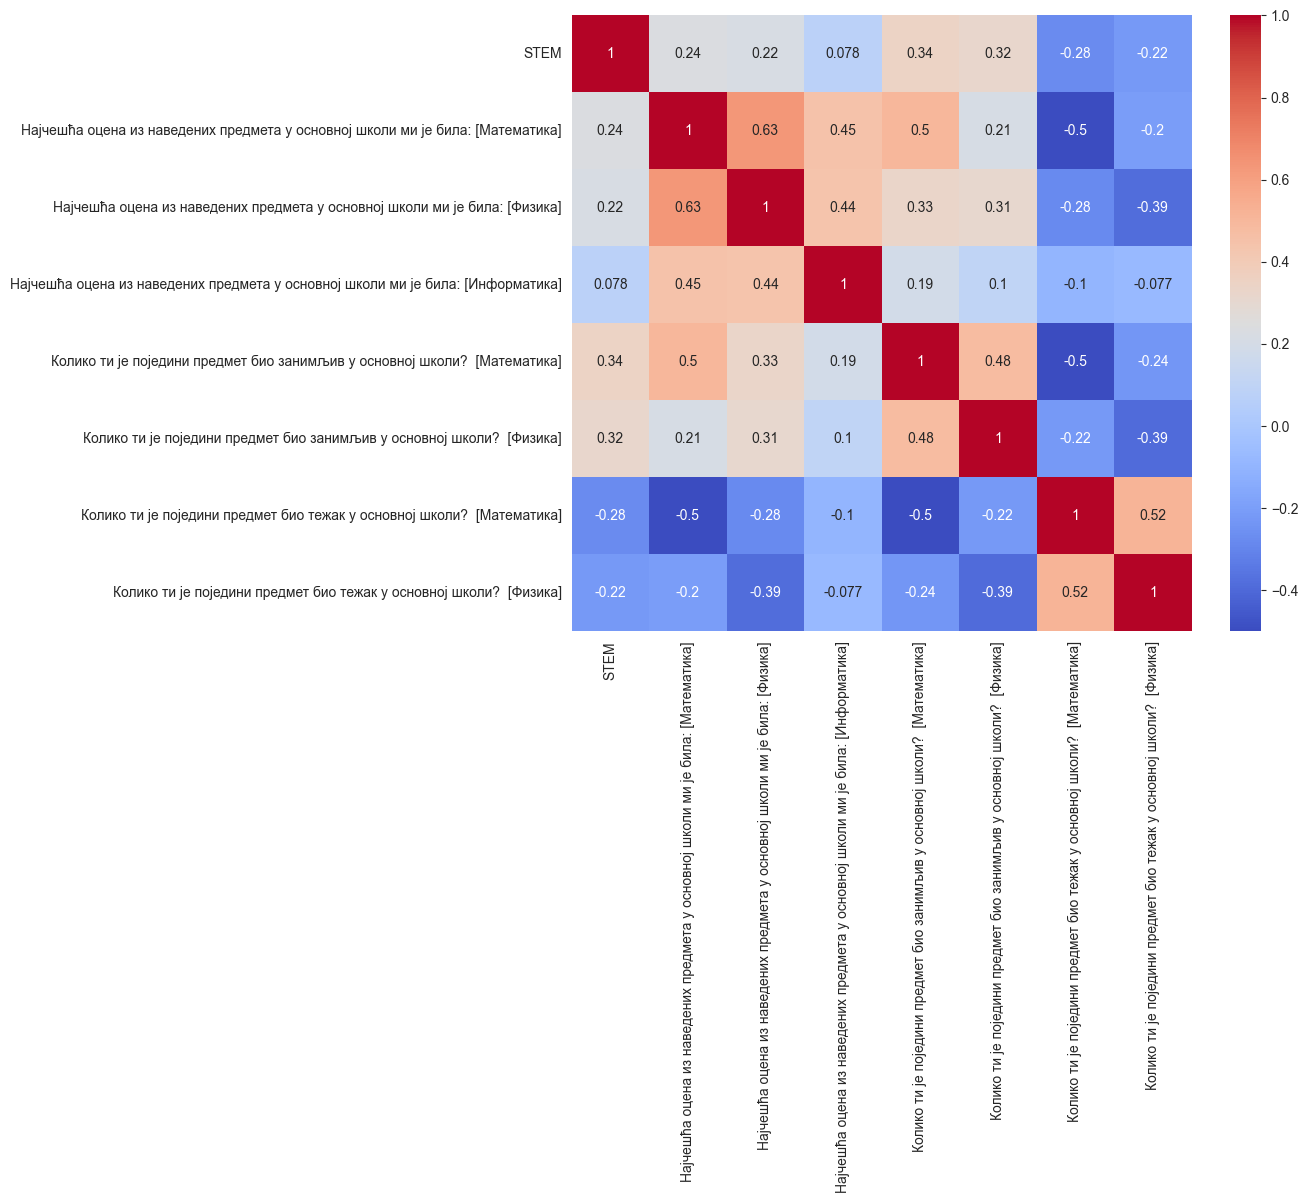

In [21]:
plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.show()

## Статистички тестови

- **t-тест за независне узорке** (исправљена варијанта): поређење средње вредности ординално/нумеричке променљиве између STEM и не-STEM групе (под претпоставком приближно нормалне расподеле уз веће $n$; за чисто ординалне податке често се користе и непараметријски тестови).
- **$\chi^2$ тест независности**: за две категоријске променљиве (нпр. пол × STEM) на контингенцијској табели.

### t-тест (занимљивост математике: STEM vs не-STEM)

`ttest_ind` пореди две групе на истој Ликерт скали (након енкодирања у претходној секцији). Проверити претпоставке у тексту рада.

In [22]:
col_zanimljivost_mat = 'Колико ти је поједини предмет био занимљив у основној школи?  [Математика]'
stem_vals = X.loc[X['STEM'] == 1, col_zanimljivost_mat].dropna()
non_stem_vals = X.loc[X['STEM'] == 0, col_zanimljivost_mat].dropna()

res = ttest_ind(stem_vals, non_stem_vals, equal_var=False)
print(res)
print(f'p-value = {res.pvalue:.6f}')

TtestResult(statistic=np.float64(12.143218967097747), pvalue=np.float64(9.384005278406585e-32), df=np.float64(1001.877450769507))
p-value = 0.000000


### $\chi^2$ тест независности (пол × STEM)

Градимо контингенцијску табелу и примењујемо `chi2_contingency` из SciPy.

In [23]:
ct = pd.crosstab(X['Пол:'], X['STEM'], margins=True)
print(ct)

ct_core = pd.crosstab(X['Пол:'], X['STEM'])
chi2, p, dof, expected = chi2_contingency(ct_core)
print(f'χ² = {chi2:.4f}, p-value = {p:.6f}, степени слободе = {dof}')

STEM      0    1   All
Пол:                  
женски  476  239   715
мушки   134  195   329
All     610  434  1044
χ² = 60.8990, p-value = 0.000000, степени слободе = 1
